In [ ]:
import pandas as pd


In [ ]:

df = pd.read_csv("/content/sentiment_reviews_starter.csv")

print(df.head())
print(df["sentiment"].value_counts())

                                              review sentiment
0   The product arrived on time and works perfectly.  positive
1  Excellent quality for the price. I am very sat...  positive
2    The instructions were clear and setup was easy.  positive
3  Customer support answered quickly and solved m...  positive
4            Comfortable to use and feels well made.  positive
sentiment
positive    15
negative    15
neutral     15
Name: count, dtype: int64


In [ ]:
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully!
Dataset shape: (45, 2)

Column names:
['review', 'sentiment']


,review,sentiment
0,The product arrived on time and works perfectly.,positive
1,Excellent quality for the price. I am very sat...,positive
2,The instructions were clear and setup was easy.,positive
3,Customer support answered quickly and solved m...,positive
4,Comfortable to use and feels well made.,positive


In [ ]:
import re
import html
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

Total reviews: 30

Class distribution:
sentiment
positive    15
negative    15
Name: count, dtype: int64

Test Accuracy: 0.5000

Classification Report:
              precision    recall  f1-score   support

    negative       0.50      0.33      0.40         3
    positive       0.50      0.67      0.57         3

    accuracy                           0.50         6
   macro avg       0.50      0.50      0.49         6
weighted avg       0.50      0.50      0.49         6



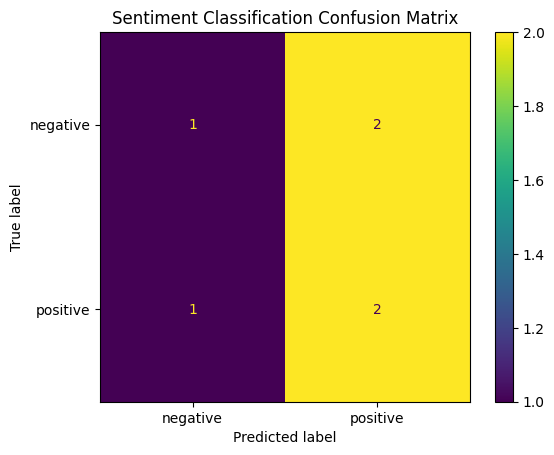

Model saved successfully!


In [ ]:
# 1. Prepare the data
df = df[["review", "sentiment"]].dropna().copy()
df["sentiment"] = df["sentiment"].str.strip().str.lower()

# Keep only labelled positive and negative reviews
df = df[df["sentiment"].isin(["positive", "negative"])]

# 2. Clean the review text
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["review"] = df["review"].apply(clean_text)

X = df["review"]
y = df["sentiment"]

print("Total reviews:", len(df))
print("\nClass distribution:")
print(y.value_counts())

# 3. Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 4. Create the ML pipeline
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# 5. Train the model
model.fit(X_train, y_train)

# 6. Evaluate on unseen test data
predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
print(f"\nTest Accuracy: {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, predictions))

# 7. Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions
)
plt.title("Sentiment Classification Confusion Matrix")
plt.show()

# 8. Save the trained model
joblib.dump(model, "sentiment_model.joblib")
print("Model saved successfully!")


In [ ]:
review = input("Enter a movie review: ")

prediction = model.predict([review])[0]
probabilities = model.predict_proba([review])[0]
confidence = max(probabilities) * 100

print("Predicted sentiment:", prediction.title())
print(f"Model confidence: {confidence:.2f}%")

Enter a movie review: this movie was fantastic
Predicted sentiment: Positive
Model confidence: 56.58%


In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nFirst 5 reviews:")
display(df.head())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())


Dataset shape: (30, 2)

Column names: ['review', 'sentiment']

First 5 reviews:


,review,sentiment
0,The product arrived on time and works perfectly.,positive
1,Excellent quality for the price. I am very sat...,positive
2,The instructions were clear and setup was easy.,positive
3,Customer support answered quickly and solved m...,positive
4,Comfortable to use and feels well made.,positive



Sentiment distribution:
sentiment
positive    15
negative    15
Name: count, dtype: int64


In [ ]:

import re
import html

# Remove missing reviews and labels
df = df[["review", "sentiment"]].dropna().copy()

# Standardize sentiment labels
df["sentiment"] = df["sentiment"].str.strip().str.lower()

# Keep positive and negative reviews
df = df[df["sentiment"].isin(["positive", "negative"])].copy()

# Clean the review text
def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["review"] = df["review"].apply(clean_text)

print("Cleaned dataset shape:", df.shape)
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

display(df.head())


Cleaned dataset shape: (30, 2)

Sentiment distribution:
sentiment
positive    15
negative    15
Name: count, dtype: int64


,review,sentiment
0,The product arrived on time and works perfectly.,positive
1,Excellent quality for the price. I am very sat...,positive
2,The instructions were clear and setup was easy.,positive
3,Customer support answered quickly and solved m...,positive
4,Comfortable to use and feels well made.,positive


Test Accuracy: 50.0 %

Classification Report:
              precision    recall  f1-score   support

    negative       0.50      0.33      0.40         3
    positive       0.50      0.67      0.57         3

    accuracy                           0.50         6
   macro avg       0.50      0.50      0.49         6
weighted avg       0.50      0.50      0.49         6



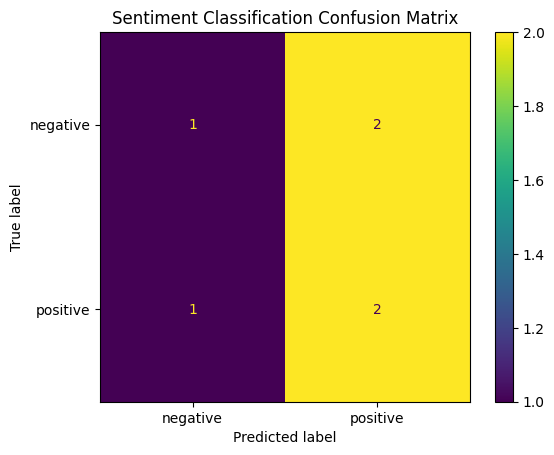

In [ ]:
predictions = model.predict(X_test)

print("Test Accuracy:", round(
    accuracy_score(y_test, predictions) * 100, 2
), "%")

print("\nClassification Report:")
print(classification_report(y_test, predictions))

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions
)
plt.title("Sentiment Classification Confusion Matrix")
plt.show()

In [ ]:
joblib.dump(model, "sentiment_model.joblib")
print("Model saved successfully!")

test_reviews = [
    "The movie was fantastic and I loved every moment.",
    "The movie was boring and a complete waste of time."
]

for review in test_reviews:
    prediction = model.predict([review])[0]
    print("\nReview:", review)
    print("Predicted sentiment:", prediction.title())


Model saved successfully!

Review: The movie was fantastic and I loved every moment.
Predicted sentiment: Positive

Review: The movie was boring and a complete waste of time.
Predicted sentiment: Positive


In [12]:
import joblib

joblib.dump(model, "sentiment_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [13]:
import joblib

joblib.dump(model, "/content/sentiment_model.joblib")

print("Model saved successfully!")

Model saved successfully!
